# Kiva-Kredite: Explorative Datenanalyse und Dashboard

**Abschlussprojekt Data Analyst** · Aileen Hertel · Oktober 2026

**Ziel:** Den Kiva-Datensatz kennenlernen, Muster und Auffälligkeiten finden und ein interaktives Dashboard erstellen.

Die drei bewerteten Grafiken sind mit **📊 Visualisierung 1–3 (zur Bewertung)** gekennzeichnet.

**Inhalt**
1. [Daten kennenlernen](#1.-Daten-kennenlernen)
2. [Datenbereinigung](#2.-Datenbereinigung)
3. [Univariate Analyse](#3.-Univariate-Analyse)
4. [Bivariate Analyse](#4.-Bivariate-Analyse)
5. [Interaktives Dashboard](#5.-Interaktives-Dashboard)
6. [Fazit](#6.-Fazit)

---

## CRISP-DM – Business Understanding
Kiva ist eine Online-Plattform, die Kredite vermittelt. Menschen und kleine Unternehmen beantragen dort Geld
für ein Vorhaben, etwa für die Landwirtschaft, einen kleinen Laden oder eine Ausbildung.
Finanziert werden die Kredite von Geldgebern, meist von mehreren gemeinsam.
Die Kreditnehmer erhalten den finanzierten Betrag und zahlen ihn über eine festgelegte Laufzeit zurück.

> **Annahmen zum Geschäftsmodell**
> - Alle Kredite sind abgeschlossen, die Finanzierungsphase ist beendet.
> - Jeder Kredit wurde ausgezahlt, auch wenn der gewünschte Betrag nicht vollständig erreicht wurde.
> - Die Daten zeigen die Kredite der letzten Jahre.

## CRISP-DM – Data Understanding

**Wofür stehen die Spalten?**

| Spalte | Bedeutung |
|---|---|
| `funded_amount` | Finanzierter, also ausgezahlter Betrag (USD) |
| `loan_amount` | Beantragter Betrag (USD) |
| `activity` | Genaue Tätigkeit, z. B. „Rickshaw“ oder „Dairy“ |
| `sector` | Oberkategorie der Tätigkeit, z. B. „Agriculture“ |
| `use` | Verwendungszweck als freier Text |
| `country_code` | Ländercode mit 2 Buchstaben |
| `country` | Land der Kreditnehmer |
| `region` | Region oder Ort der Kreditnehmer |
| `currency` | Währung, in der der finanzierte Betrag ausgezahlt wurde |
| `term_in_months` | Laufzeit in Monaten |
| `lender_count` | Anzahl der Geldgeber, die Geld gegeben haben |
| `borrower_genders` | Geschlecht und Anzahl der Kreditnehmer (bei Gruppen mehrere Angaben) |
| `repayment_interval` | Art der Rückzahlung, z. B. monatlich oder unregelmäßig |

---

## 1. Daten kennenlernen

### 1.1 Daten laden
Die Spalten der Datei sind mit `#` statt mit Komma getrennt.
Die erste Spalte ist eine laufende Nummer ohne Namen und wird zum Index.

In [1]:
# benötigte Bibliotheken importieren

## für die Daten
import pandas as pd

## für die Visualisierung
import plotly.express as px

## für die Dash-App
from dash import Dash
from dash import dcc                         # Datenauswahl (Dropdown) und Grafik
from dash import html                        # Layout, z. B. Überschrift
from dash.dependencies import Input, Output  # für den Callback

In [2]:
# Pfad zur Datei
datei = "data/data_abschlussprojekt.csv"

# Daten einlesen
# sep="#"      -> die Spalten sind mit # getrennt
# index_col=0  -> die erste Spalte (laufende Nummer) wird der Index
df = pd.read_csv(datei, sep="#", index_col=0)
df.head(n=5)

,funded_amount,loan_amount,activity,sector,use,country_code,country,region,currency,term_in_months,lender_count,borrower_genders,repayment_interval
0,300.0,300.0,Fruits & Vegetables,Food,"To buy seasonal, fresh fruits to sell.",PK,Pakistan,Lahore,PKR,12.0,12,female,irregular
1,575.0,575.0,Rickshaw,Transportation,to repair and maintain the auto rickshaw used ...,PK,Pakistan,Lahore,PKR,11.0,14,"female, female",irregular
2,150.0,150.0,Transportation,Transportation,To repair their old cycle-van and buy another ...,IN,India,Maynaguri,INR,43.0,6,female,bullet
3,200.0,200.0,Embroidery,Arts,to purchase an embroidery machine and a variet...,PK,Pakistan,Lahore,PKR,11.0,8,female,irregular
4,400.0,400.0,Milk Sales,Food,to purchase one buffalo.,PK,Pakistan,Abdul Hakeem,PKR,14.0,16,female,monthly


### 1.2 Datensatz kennenlernen

In [3]:
# Wie viele Zeilen und Spalten hat der Datensatz?
df.shape

(671205, 13)

In [4]:
# Anzahl der Zeilen speichern (für die Berechnung von Anteilen)
count_rows = df.shape[0]
count_rows

671205

In [5]:
# Wie heißen die Spalten?
df.columns

Index([' funded_amount', ' loan_amount', ' activity', ' sector', ' use',
       ' country_code', ' country', ' region', ' currency', ' term_in_months',
       ' lender_count', ' borrower_genders', ' repayment_interval'],
      dtype='str')

**Beobachtung:** Die Spaltennamen enthalten Leerzeichen. Sie werden entfernt, damit der Zugriff auf die Spalten einfacher wird.

In [6]:
# Leerzeichen am Anfang und Ende der Spaltennamen entfernen
df.columns = df.columns.str.strip()

# check
df.columns

Index(['funded_amount', 'loan_amount', 'activity', 'sector', 'use',
       'country_code', 'country', 'region', 'currency', 'term_in_months',
       'lender_count', 'borrower_genders', 'repayment_interval'],
      dtype='str')

**Beobachtung:** Der Datensatz enthält 671.205 Kredite und 13 Spalten. `currency` ist die Währung,
in der ausgezahlt wurde (z. B. PKR, INR, USD). Die Beträge selbst sind einheitlich in USD angegeben.

**Brainstorming**
- `loan_amount` und `funded_amount` → Erreichen die Kredite ihren beantragten Betrag?
- `sector` und `activity` → Wofür werden Kredite vergeben, und welche Sektoren erhalten die größte Summe?
- `country` und `region` → Aus welchen Ländern kommen die Kredite?
- `borrower_genders` → Oft stehen mehrere Personen in einer Zelle. Die Spalte muss erst aufbereitet werden.
- `term_in_months` und `repayment_interval` → Wie lange laufen die Kredite, und wie wird zurückgezahlt?
- `lender_count` → Gibt es Kredite ganz ohne Geldgeber?
- `use` → Wofür genau wird das Geld verwendet? (Freitext, schwer auszuwerten)

**Fokus:** Aus dem Brainstorming werden zwei Punkte weiterverfolgt: Auf welche Sektoren entfällt die finanzierte Summe,
und welche Kredite erreichen ihren Betrag nicht? Dafür reichen Betrag, Sektor, Land und Kreditnehmer.
Die übrigen Spalten bleiben bewusst außen vor.

### 1.3 Datentypen und fehlende Werte

In [7]:
# Datentypen anschauen
df.dtypes

funded_amount         float64
loan_amount           float64
activity                  str
sector                    str
use                       str
country_code              str
country                   str
region                    str
currency                  str
term_in_months        float64
lender_count            int64
borrower_genders          str
repayment_interval        str
dtype: object

In [8]:
# Wie viele fehlende Werte gibt es pro Spalte? (absteigend sortiert)
df.isnull().sum().sort_values(ascending=False)

region                56800
use                    4232
borrower_genders       4221
country_code              8
funded_amount             0
sector                    0
activity                  0
loan_amount               0
country                   0
currency                  0
term_in_months            0
lender_count              0
repayment_interval        0
dtype: int64

**Abgleich: Skalenniveau (Inhalt der Spalte) vs. technischer Datentyp**

| Spalte | Skalenniveau | technischer Datentyp | passt? |
|---|---|---|---|
| `funded_amount`, `loan_amount` | Verhältnisskala (Geldbeträge) | `float64` (Kommazahl) | ja |
| `lender_count` | Verhältnisskala (Anzahl) | `int64` (ganze Zahl) | ja |
| `term_in_months` | Verhältnisskala (Monate) | `float64` (Kommazahl) | prüfen |
| `activity`, `sector`, `use`, `country_code`, `country`, `region`, `currency`, `borrower_genders`, `repayment_interval` | nominal (Kategorien ohne Rangfolge) | `str` (Text) | ja |

**Beobachtung:** Bis auf `term_in_months` passen die Datentypen: Beträge und Anzahlen sind Zahlen, Kategorien sind Text.
`term_in_months` ist als Kommazahl gespeichert (z. B. 12.0), die Laufzeit wird aber in ganzen Monaten angegeben.
Vor einer Umwandlung in ganze Zahlen wird deshalb geprüft, ob es echte Kommastellen gibt.
Fehlende Werte gibt es in vier Spalten: `use`, `country_code`, `region` und `borrower_genders`.

### 1.4 Fehlende Werte genauer prüfen

In [9]:
# Anteil der fehlenden Werte in Prozent pro Spalte (absteigend sortiert)
(df.isnull().mean() * 100).round(2).sort_values(ascending=False)

region                8.46
borrower_genders      0.63
use                   0.63
funded_amount         0.00
loan_amount           0.00
sector                0.00
activity              0.00
country               0.00
country_code          0.00
currency              0.00
term_in_months        0.00
lender_count          0.00
repayment_interval    0.00
dtype: float64

In [10]:
# Welche Länder haben keinen Ländercode?
df.loc[df["country_code"].isnull(), "country"].value_counts()

country
Namibia    8
Name: count, dtype: int64

In [11]:
# Nur die Kredite, bei denen die Angabe zum Geschlecht fehlt
kredite_geschlecht_fehlt = df.loc[df["borrower_genders"].isnull(), :]

# Welche Angaben fehlen bei diesen Krediten noch?
kredite_geschlecht_fehlt.isnull().sum()

funded_amount            0
loan_amount              0
activity                 0
sector                   0
use                   4221
country_code             0
country                  0
region                4221
currency                 0
term_in_months           0
lender_count             0
borrower_genders      4221
repayment_interval       0
dtype: int64

In [12]:
# Anteil nicht voll finanzierter Kredite in %: ohne Angabe zum Geschlecht und bei allen Krediten
nicht_voll_fehlt = kredite_geschlecht_fehlt.loc[kredite_geschlecht_fehlt["funded_amount"] < kredite_geschlecht_fehlt["loan_amount"], :].shape[0]
print("ohne Angabe zum Geschlecht:", round(nicht_voll_fehlt / kredite_geschlecht_fehlt.shape[0] * 100, 1))

nicht_voll_alle = df.loc[df["funded_amount"] < df["loan_amount"], :].shape[0]
print("alle Kredite:", round(nicht_voll_alle / count_rows * 100, 1))

ohne Angabe zum Geschlecht: 16.2
alle Kredite: 7.2


**Beobachtung:**
- `country_code`: Alle 8 fehlenden Werte gehören zu Namibia. Dessen Ländercode lautet „NA“,
  und genau das liest pandas als fehlenden Wert. Die Angabe fehlt also gar nicht.
- `region`: Mit 8,46 % ist das die größte Lücke.
- Bei allen 4.221 Krediten, bei denen die Angabe zum Geschlecht fehlt, fehlen auch use und region. Alle anderen Angaben sind bei diesen Krediten vorhanden.

**Einordnung der fehlenden Werte (MCAR / MAR / MNAR)**
- `country_code`: kein echter fehlender Wert, sondern ein Fehler beim Einlesen. → Ländercode wieder eintragen.
- `region`: Die Region gehört nicht zum Fokus der Analyse (siehe 1.2). Ob das Fehlen von einer anderen Spalte
  abhängt (MAR), wird deshalb nicht geprüft. MCAR und MNAR lassen sich ohne Nachfrage nicht unterscheiden.
  → eigene Kategorie *Unknown*
- `borrower_genders`: Bei allen 4.221 Krediten ohne Angabe zum Geschlecht fehlt auch `use`. Diese Kredite sind deutlich häufiger nicht voll finanziert (16,2 % statt 7,2 %). Das Fehlen hängt also mit einer anderen Spalte zusammen. Das spricht gegen MCAR und für MAR. MNAR lässt sich ohne Nachfrage nicht ausschließen. → eigene Kategorie Unknown
- `use`: Freitext, nicht im Fokus der Analyse. → eigene Kategorie Unknown

---

## 2. Datenbereinigung

*CRISP-DM: Data Preparation*

### 2.1 Fehlende Werte behandeln
Zeilen werden nicht gelöscht, sonst würden ihre Beträge in allen Summen und Grafiken fehlen.
Stattdessen gibt es für jede Spalte eine eigene Lösung:
- `country_code`: Für Namibia wird wieder „NA“ eingetragen.
- `region`, `use`, `borrower_genders`: Lücken werden mit *Unknown* gekennzeichnet, damit sichtbar bleibt, wo eine Angabe fehlt.

In [13]:
# Ländercode für Namibia eintragen
df.loc[df["country"] == "Namibia", "country_code"] = "NA"

# Fehlende Texte mit "Unknown" kennzeichnen
df.loc[df["region"].isnull(), "region"] = "Unknown"
df.loc[df["use"].isnull(), "use"] = "Unknown"
df.loc[df["borrower_genders"].isnull(), "borrower_genders"] = "Unknown"

In [14]:
# check: Gibt es noch fehlende Werte?
df.isnull().sum()

funded_amount         0
loan_amount           0
activity              0
sector                0
use                   0
country_code          0
country               0
region                0
currency              0
term_in_months        0
lender_count          0
borrower_genders      0
repayment_interval    0
dtype: int64

**Beobachtung:** Es gibt keine fehlenden Werte (NaN) mehr. Wo eine Angabe fehlte, steht jetzt *Unknown*.

**Bias-Check**
- Verändert sich die Verteilung? Die Lücken wurden nicht mit geschätzten Werten aufgefüllt.
  Die vorhandenen Angaben bleiben unverändert.
- Wird eine Gruppe benachteiligt? Alle Kredite bleiben im Datensatz. Kredite ohne Angabe zum Geschlecht
  bilden eine eigene Gruppe *Unknown*. Die Gruppe Unknown ist häufiger nicht voll finanziert (siehe 1.4), umfasst aber nur 0,6 % der Kredite. Eine deutliche Verzerrung des Vergleichs zwischen Frauen und Männern ist deshalb nicht zu erwarten.

### 2.2 Datentypen anpassen
Vor der Umwandlung in ganze Zahlen wird geprüft, ob `term_in_months` echte Kommastellen enthält.

In [15]:
# Wie viele Laufzeiten haben echte Kommastellen?
# Idee: Eine ganze Zahl bleibt beim Runden gleich
mit_komma = df.loc[df["term_in_months"] != df["term_in_months"].round(0), :]
mit_komma.shape[0]

0

In [16]:
# In ganze Zahlen umwandeln
df = df.astype({"term_in_months": int})

# check
df.dtypes

funded_amount         float64
loan_amount           float64
activity                  str
sector                    str
use                       str
country_code              str
country                   str
region                    str
currency                  str
term_in_months          int64
lender_count            int64
borrower_genders          str
repayment_interval        str
dtype: object

**Beobachtung:** Keine Laufzeit hat Kommastellen, die Umwandlung verändert also keinen Wert.

### 2.3 Doppelte Zeilen prüfen

**Vorüberlegung**

Der Datensatz hat keine Kredit-Nummer, an der man einen Kredit eindeutig erkennt.
Als doppelt gilt deshalb eine Zeile, die in allen Spalten mit einer anderen Zeile übereinstimmt.

**Ermittlung**

In [17]:
# Wie viele Zeilen sind komplett identisch mit einer anderen Zeile?
anzahl_doppelt = df.loc[df.duplicated(), :].shape[0]
anzahl_doppelt

24372

In [18]:
# Anteil an allen Zeilen in Prozent
round(anzahl_doppelt / count_rows * 100, 1)

3.6

In [19]:
# Anteil der doppelten Zeilen an der finanzierten Gesamtsumme in Prozent
summe_doppelt = df.loc[df.duplicated(), "funded_amount"].sum()
summe_gesamt = df.loc[:, "funded_amount"].sum()
round(summe_doppelt / summe_gesamt * 100, 1)

np.float64(1.0)

In [20]:
# Beispiel anschauen
df.loc[df.duplicated(keep=False), :].head(n=6)

,funded_amount,loan_amount,activity,sector,use,country_code,country,region,currency,term_in_months,lender_count,borrower_genders,repayment_interval
327,275.0,275.0,Farming,Agriculture,to buy fertilizers and other farm supplies.,PH,Philippines,"Brookes Point, Palawan",PHP,8,8,female,irregular
392,100.0,100.0,Home Energy,Personal Use,to buy a solar lamp.,SV,El Salvador,Unknown,USD,14,4,male,monthly
405,100.0,100.0,Home Energy,Personal Use,to buy a solar-powered lamp.,SV,El Salvador,Unknown,USD,14,4,male,monthly
498,100.0,100.0,Home Energy,Personal Use,to buy a solar-powered lamp.,SV,El Salvador,Unknown,USD,14,4,male,monthly
606,100.0,100.0,Home Energy,Personal Use,to buy a solar-powered lamp.,SV,El Salvador,Unknown,USD,14,4,male,monthly
652,250.0,250.0,Dairy,Agriculture,to purchase a dairy cow to start a milk supply...,IN,India,Dhupguri,INR,43,9,female,bullet


**Beobachtung:** 24.372 Zeilen (ca. 3,6 %) wiederholen eine frühere Zeile vollständig.
Im Beispiel oben sind das drei gleiche Kredite von je 100 USD für eine Solarlampe in El Salvador (Zeilen 405, 498 und 606).
*Weil der Datensatz keine Kredit-Nummer enthält, kann es sich trotzdem um verschiedene Kredite handeln.*

**Umgang:** Die Zeilen bleiben im Datensatz, damit keine echten Kredite verloren gehen. Ohne Kredit-Nummer lässt sich nicht klären, ob doppelt erfasste Kredite dabei sind. Die doppelten Zeilen machen 3,6 % der Kredite aus, aber nur 1,0 % der finanzierten Summe. Wären alle Wiederholungen Fehler, läge die Gesamtsumme also um höchstens 1,0 % zu hoch.

### 2.4 Plausibilität und Ausreißer
Sind die Zahlen sinnvoll? Geprüft werden auffällig kleine oder große Werte, Kredite,
die mehr erhalten haben als beantragt, und Kredite ohne Geldgeber oder ohne finanzierten Betrag.

In [21]:
# Statistische Übersicht der Zahlenspalten
df.describe().round(2)

,funded_amount,loan_amount,term_in_months,lender_count
count,671205.0,671205.00,671205.00,671205.00
mean,786.0,842.40,13.74,20.59
std,1130.4,1198.66,8.60,28.46
min,0.0,25.00,1.00,0.00
25%,250.0,275.00,8.00,7.00
50%,450.0,500.00,13.00,13.00
75%,900.0,1000.00,14.00,24.00
max,100000.0,100000.00,158.00,2986.00


In [22]:
# Mehr finanziert als beantragt?
mehr_als_beantragt = df.loc[df["funded_amount"] > df["loan_amount"], :]
print("Mehr finanziert als beantragt:", mehr_als_beantragt.shape[0])

# Weniger finanziert als beantragt?
weniger_als_beantragt = df.loc[df["funded_amount"] < df["loan_amount"], :]
print("Weniger finanziert als beantragt:", weniger_als_beantragt.shape[0])

# Kredite mit 0 Finanzierung
null_finanziert = df.loc[df["funded_amount"] == 0, :]
print("Kredite mit 0 Finanzierung:", null_finanziert.shape[0])

# Kredite ohne Geldgeber
null_lender = df.loc[df["lender_count"] == 0, :]
print("Kredite ohne Geldgeber:", null_lender.shape[0])

Mehr finanziert als beantragt: 2
Weniger finanziert als beantragt: 48328
Kredite mit 0 Finanzierung: 3383
Kredite ohne Geldgeber: 3383


In [23]:
# Sind die Kredite mit 0 Finanzierung dieselben wie die ohne Geldgeber?
beide_null = df.loc[(df["funded_amount"] == 0) & (df["lender_count"] == 0), :]
print("0 USD finanziert und ohne Geldgeber:", beide_null.shape[0])

# Die 2 Kredite anschauen, die mehr bekommen haben als beantragt
mehr_als_beantragt

0 USD finanziert und ohne Geldgeber: 3383


,funded_amount,loan_amount,activity,sector,use,country_code,country,region,currency,term_in_months,lender_count,borrower_genders,repayment_interval
277188,425.0,400.0,General Store,Retail,"to buy beverages, rice, laundry detergent, sug...",MZ,Mozambique,"Boane, Maputo",MZN,17,11,male,monthly
338159,3400.0,3000.0,Farm Supplies,Agriculture,"to pay for wires for the grape orchard, cover ...",AM,Armenia,"Hoktember village, Armavir region",USD,38,84,male,monthly


**Beobachtung:**
- Der Median des beantragten Betrags liegt bei 500 USD. Einzelne sehr große Kredite (bis 100.000 USD) heben den Mittelwert auf 842 USD.
- Negative Werte gibt es nicht. Der kleinste Betrag liegt bei 25 USD, die kürzeste Laufzeit bei einem Monat.
- 48.328 Kredite (7,2 %) sind nicht voll finanziert.
- 3.383 Kredite haben einen finanzierten Betrag von 0 USD. Es sind genau die Kredite ohne Geldgeber.
  Ausgezahlt wird der erhaltene Betrag, bei diesen Krediten also 0 USD.
- 2 Kredite haben etwas mehr erhalten als beantragt (425 statt 400 USD und 3.400 statt 3.000 USD).

**Umgang:** Alle diese Kredite bleiben im Datensatz (siehe Annahmen zum Geschäftsmodell).
Die beiden überfinanzierten Kredite zählen als *fully funded*. Bei 2 von 671.205 Krediten ist ihr Einfluss vernachlässigbar.

**Ausreißer bei der Kredithöhe**

Die beantragten Beträge reichen von 25 bis 100.000 USD. Ob die großen Kredite Ausreißer sind, wird rechnerisch
mit dem Interquartilsabstand (IQR) geprüft.

In [24]:
# Grenzen für Ausreißer berechnen (IQR-Methode)
Q1 = df.loc[:, "loan_amount"].quantile(0.25)
Q3 = df.loc[:, "loan_amount"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

print("untere Grenze in USD:", lower)
print("obere Grenze in USD:", upper)

untere Grenze in USD: -812.5
obere Grenze in USD: 2087.5


In [25]:
# Wie viele Kredite liegen über der oberen Grenze?
ausreisser_oben = df.loc[df["loan_amount"] > upper, :]
print("Kredite über der oberen Grenze:", ausreisser_oben.shape[0])
print("Anteil in %:", round(ausreisser_oben.shape[0] / count_rows * 100, 1))

# Wie viele Kredite liegen unter der unteren Grenze?
ausreisser_unten = df.loc[df["loan_amount"] < lower, :]
print("Kredite unter der unteren Grenze:", ausreisser_unten.shape[0])

Kredite über der oberen Grenze: 50993
Anteil in %: 7.6
Kredite unter der unteren Grenze: 0


**Beobachtung:** Die obere Grenze liegt bei 2.087,5 USD. 50.993 Kredite (7,6 %) liegen darüber.
Die untere Grenze liegt bei -812,5 USD. Darunter liegt kein Kredit, nach unten gibt es also keine Ausreißer.

**Umgang:** Ob ein Wert ein Ausreißer ist, hängt vom Kontext ab. Die IQR-Grenze zeigt, welche Beträge statistisch
auffällig sind. Ein Datenfehler ist damit nicht nachgewiesen. Große Kredite sind bei Gruppen und kleinen Unternehmen
möglich. Die Kredite bleiben deshalb unverändert im Datensatz.
Weil sie den Mittelwert nach oben ziehen, wird für den typischen Kreditbetrag im Folgenden der Median verwendet.

### 2.5 Neue Spalte: Finanzierungsstatus
Für die weitere Auswertung bekommt jeder Kredit einen Status:
- *fully funded:* beantragter Betrag erreicht oder überschritten
- *partially funded:* mehr als 0 USD, aber weniger als beantragt
- *not funded:* 0 USD finanziert

Zusätzlich gibt es die Spalte `nicht_voll`. Sie ist *True*, wenn ein Kredit teilweise oder gar nicht finanziert ist.

In [26]:
# Startwert: Alle Kredite gelten zuerst als voll finanziert
df.loc[:, "funding_status"] = "fully funded"

# Weniger finanziert als beantragt -> teilweise finanziert
df.loc[df["funded_amount"] < df["loan_amount"], "funding_status"] = "partially funded"

# 0 USD finanziert -> gar nicht finanziert
df.loc[df["funded_amount"] == 0, "funding_status"] = "not funded"

# Hilfsspalte: True, wenn der Kredit nicht voll finanziert ist (teilweise oder gar nicht)
df.loc[:, "nicht_voll"] = df.loc[:, "funding_status"] != "fully funded"

In [27]:
# check: Wie viele Kredite gibt es pro Status?
df.loc[:, "funding_status"].value_counts()

funding_status
fully funded        622877
partially funded     44945
not funded            3383
Name: count, dtype: int64

In [28]:
# Und in Prozent
(df.loc[:, "funding_status"].value_counts() / count_rows * 100).round(2)

funding_status
fully funded        92.8
partially funded     6.7
not funded           0.5
Name: count, dtype: float64

**Beobachtung:** 92,8 % der Kredite sind voll finanziert, 6,7 % teilweise und 0,5 % gar nicht.
Interessant ist also, was die nicht voll finanzierten Kredite unterscheidet.

### 2.6 Zusammenfassung der Datenbereinigung

> - Datei mit `#` als Trennzeichen geladen, Spaltennamen bereinigt
> - Namibia-Code „NA“ wiederhergestellt, fehlende Angaben als *Unknown* gekennzeichnet
> - `term_in_months` in ganze Zahlen umgewandelt
> - doppelte Zeilen und nicht voll finanzierte Kredite behalten
> - große Kredite geprüft und als plausibel behalten
> - neue Spalten `funding_status` und `nicht_voll` angelegt
>
> Der Datensatz umfasst weiterhin 671.205 Kredite.

---

## 3. Univariate Analyse
Zuerst werden einzelne Spalten für sich betrachtet: Wie sind die Werte verteilt?

### 3.1 Wie hoch sind die beantragten Kredite?

#### 📊 Visualisierung 1 (zur Bewertung)

**Vorüberlegung**

Um die Verteilung eines Betrags zu zeigen, eignet sich ein Histogramm.
Gezeigt werden nur Kredite bis 3.000 USD, da einzelne sehr große Kredite die Grafik sonst unlesbar machen würden.

In [29]:
# Nur Kredite bis 3.000 USD für die Grafik nehmen
# .copy() -> eigene Kopie, damit gleich eine neue Spalte angelegt werden kann
kredite_bis_3000 = df.loc[df["loan_amount"] <= 3000, :].copy()

# Wie viel Prozent aller Kredite sind das?
anteil_bis_3000 = kredite_bis_3000.shape[0] / count_rows * 100
print("Anteil der Kredite bis 3.000 USD in %:", round(anteil_bis_3000, 1))

# Median des beantragten Betrags (alle Kredite)
median_betrag = df.loc[:, "loan_amount"].median()
print("Median in USD:", median_betrag)

# Die 5 häufigsten Kreditbeträge
df.loc[:, "loan_amount"].value_counts().head(5)

Anteil der Kredite bis 3.000 USD in %: 95.7
Median in USD: 500.0


loan_amount
225.0    33157
300.0    30315
500.0    29035
200.0    26214
250.0    25568
Name: count, dtype: int64

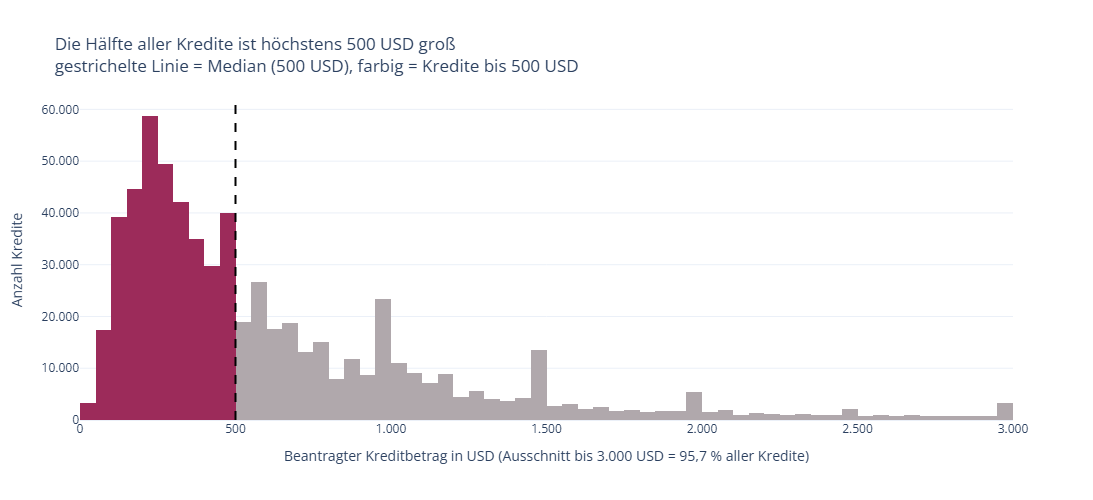

In [30]:
# Neue Spalte für die Farbe: Kredite bis 500 USD (Median) in Beere, alle anderen in Grau
kredite_bis_3000.loc[:, "bereich"] = "über 500 USD"
kredite_bis_3000.loc[kredite_bis_3000["loan_amount"] <= 500, "bereich"] = "bis 500 USD"

# Grafik erstellen
my_hist = px.histogram(data_frame=kredite_bis_3000,
                       x="loan_amount",
                       color="bereich",
                       color_discrete_map={"bis 500 USD": "#9C2B5A", "über 500 USD": "#B0A8AC"},
                       title="Die Hälfte aller Kredite ist höchstens 500 USD groß"
                             + "<br>gestrichelte Linie = Median (500 USD), farbig = Kredite bis 500 USD",
                       labels={"loan_amount": "Beantragter Kreditbetrag in USD (Ausschnitt bis 3.000 USD = "
                                              + str(round(anteil_bis_3000, 1)).replace(".", ",") + " % aller Kredite)"},
                       template="plotly_white",
                       height=500
                       )

# Gleiche Balkenbreite (50 USD) für beide Farben
# start=0.001 -> ein Kredit über genau 500 USD liegt noch im Balken bis 500 USD
my_hist.update_traces(xbins=dict(start=0.001, end=3000.001, size=50))

# Beschriftung der y-Achse
# tickformat=",d" -> ganze Zahlen mit Tausenderpunkt, z. B. 60.000 statt 60k
my_hist.update_yaxes(title="Anzahl Kredite", tickformat=",d")
my_hist.update_xaxes(tickformat=",d")

# Gestrichelte Linie für den Median
my_hist.add_vline(x=median_betrag,
                  line_width=2,
                  line_dash="dash",
                  line_color="black")

# Legende ausblenden, die Farbe erklärt sich über den Titel
# separators=",." -> Komma als Dezimalzeichen, Punkt als Tausendertrennzeichen
my_hist.update_layout(showlegend=False, separators=",.")

my_hist.show()

#### Analyse

**Deskriptiver Teil**

Das Histogramm zeigt, wie viele Kredite in welchen Betragsbereich fallen
(x-Achse: beantragter Betrag in USD, y-Achse: Anzahl). Die gestrichelte Linie markiert den Median.
Je höher ein Balken, desto mehr Kredite liegen in diesem Bereich.

**Analytischer Teil**

Die meisten Kredite sind klein: Der Median liegt bei 500 USD, drei Viertel der Kredite bei höchstens 1.000 USD.
Nach rechts werden die Balken insgesamt niedriger, es gibt also viele kleine und nur wenige große Kredite.
Der Mittelwert (842 USD) liegt deshalb deutlich über dem Median.
Auffällig sind außerdem Spitzen bei runden Beträgen wie 1.000, 1.500 und 2.000 USD.

Die Grafik erfasst 95,7 % aller Kredite. Die übrigen 4,3 % reichen bis 100.000 USD und bleiben im Datensatz (siehe 2.4).

### 3.2 Aus welchen Ländern kommen die Kredite?

In [31]:
# Wie viele verschiedene Länder gibt es?
print("Anzahl Länder:", df.loc[:, "country"].nunique())

# Welchen Anteil haben die 10 Länder mit den meisten Krediten?
anteil_top10_laender = df.loc[:, "country"].value_counts().head(10).sum() / count_rows * 100
print("Anteil der 10 größten Länder in %:", round(anteil_top10_laender, 1))

# Die 10 Länder mit den meisten Krediten
df.loc[:, "country"].value_counts().head(10)

Anzahl Länder: 87
Anteil der 10 größten Länder in %: 64.9


country
Philippines    160441
Kenya           75825
El Salvador     39875
Cambodia        34836
Pakistan        26857
Peru            22233
Colombia        21995
Uganda          20601
Tajikistan      19580
Ecuador         13521
Name: count, dtype: int64

**Beobachtung:** Mit Abstand die meisten Kredite stammen von den Philippinen, gefolgt von Kenia und El Salvador.
Die zehn größten der 87 Länder stellen 64,9 % der Kredite, die übrigen 77 Länder zusammen 35,1 %.

### 3.3 Zwischenfazit der univariaten Analyse

> Die meisten Kredite sind klein, und zehn Länder stellen knapp zwei Drittel der Kredite.

---

## 4. Bivariate Analyse

**Thema: Kredite und ihre Finanzierung**

Aus dem Brainstorming ergeben sich zwei Fragen: Auf welche Sektoren entfällt die größte finanzierte Summe?
Und erreichen die Kredite in allen Sektoren gleich oft ihren Betrag?

### 4.1 Auf welche Sektoren entfällt die größte Summe?

#### Daten aufbereiten
Summiert wird `funded_amount`, also der tatsächlich finanzierte Betrag.
Zusätzlich zeigt die Tabelle Anzahl und Median-Betrag pro Sektor.
Damit Grafiken und Text dieselben Namen verwenden, werden die Sektoren in der neuen Spalte `sektor` ins Deutsche übersetzt.

In [32]:
# Sektoren ins Deutsche übersetzen
sektor_deutsch = {"Agriculture": "Landwirtschaft", "Food": "Lebensmittel", "Retail": "Einzelhandel",
                  "Services": "Dienstleistungen", "Clothing": "Kleidung", "Education": "Bildung",
                  "Housing": "Wohnen", "Personal Use": "Privater Bedarf", "Arts": "Kunst",
                  "Transportation": "Transport", "Health": "Gesundheit", "Construction": "Bau",
                  "Manufacturing": "Produktion", "Entertainment": "Unterhaltung", "Wholesale": "Großhandel"}

df.loc[:, "sektor"] = df.loc[:, "sector"].map(sektor_deutsch)

# check: Wurde jeder Sektor übersetzt? (Erwartung: 0 fehlende Werte)
print("Nicht übersetzte Sektoren:", df.loc[:, "sektor"].isnull().sum())

# Daten gruppieren: Summe, Anzahl und Median pro Sektor
df_sektor = df.groupby(by="sektor", as_index=False).agg(summe_usd=("funded_amount", "sum"),
                                                        anzahl_kredite=("sektor", "count"),
                                                        median_kreditbetrag_usd=("loan_amount", "median"))

# In Millionen USD umrechnen, damit die Zahlen lesbar sind
df_sektor.loc[:, "summe_mio_usd"] = df_sektor.loc[:, "summe_usd"] / 1000000

# Sortieren: größte Summe oben
df_sektor = df_sektor.sort_values(by="summe_mio_usd", ascending=False)

# Gesamtsumme und Anteil der 3 größten Sektoren
gesamt = df_sektor.loc[:, "summe_mio_usd"].sum()
top3 = df_sektor.loc[:, "summe_mio_usd"].head(3).sum()
print("Gesamt in Mio. USD:", round(gesamt, 1))
print("Anteil der Top 3 in %:", round(top3 / gesamt * 100, 1))

# Tabelle anzeigen
df_sektor.loc[:, ["sektor", "summe_mio_usd", "anzahl_kredite", "median_kreditbetrag_usd"]].round(1)

Nicht übersetzte Sektoren: 0
Gesamt in Mio. USD: 527.6
Anteil der Top 3 in %: 64.4


,sektor,summe_mio_usd,anzahl_kredite,median_kreditbetrag_usd
8,Landwirtschaft,133.8,180302,500.0
9,Lebensmittel,115.1,136657,450.0
3,Einzelhandel,90.9,124494,425.0
2,Dienstleistungen,43.0,45140,550.0
6,Kleidung,34.8,32742,600.0
1,Bildung,30.0,31013,725.0
14,Wohnen,21.4,33731,500.0
10,Privater Bedarf,14.2,36385,200.0
7,Kunst,11.8,12060,475.0
12,Transport,9.8,15518,450.0


#### 📊 Visualisierung 2 (zur Bewertung)

**Vorüberlegung**

Gefragt ist, wie sich die gesamte finanzierte Summe auf die 15 Sektoren aufteilt. Dafür eignet sich eine Treemap:
Jeder Sektor ist ein Rechteck, und je größer die Summe, desto größer die Fläche.
So ist direkt zu sehen, welchen Teil des Ganzen die einzelnen Sektoren ausmachen.

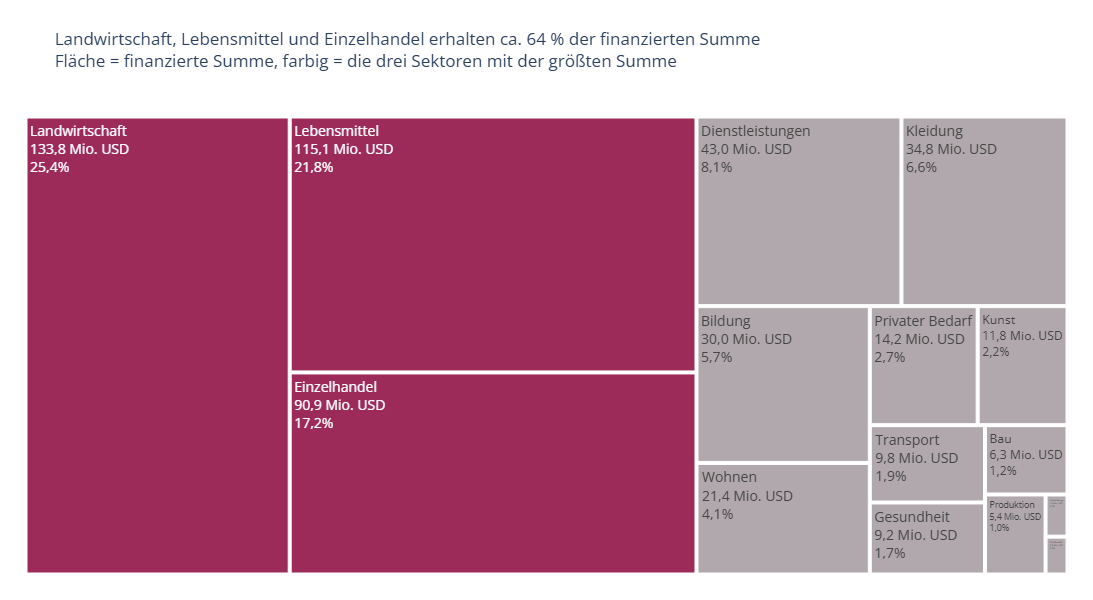

In [33]:
# Die 3 größten Sektoren
list_top3 = df_sektor.loc[:, "sektor"].head(3)

# Neue Spalte für die Farbe: Top 3 in Beere, alle anderen in Grau
df_sektor.loc[:, "farbe"] = "übrige Sektoren"
df_sektor.loc[df_sektor["sektor"].isin(list_top3), "farbe"] = "Top 3"

# Grafik erstellen
# path   -> jeder Sektor wird ein Rechteck
# values -> die Summe bestimmt die Größe der Fläche
treemap_sektor = px.treemap(data_frame=df_sektor,
                            path=["sektor"],
                            values="summe_mio_usd",
                            color="farbe",
                            color_discrete_map={"Top 3": "#9C2B5A", "übrige Sektoren": "#B0A8AC"},
                            title="Landwirtschaft, Lebensmittel und Einzelhandel erhalten ca. 64 % der finanzierten Summe"
                                  + "<br>Fläche = finanzierte Summe, farbig = die drei Sektoren mit der größten Summe",
                            height=600
                            )

# Text in jedem Rechteck: Sektor, Summe in Mio. USD und Anteil an der Gesamtsumme
treemap_sektor.update_traces(texttemplate="%{label}<br>%{value:.1f} Mio. USD<br>%{percentRoot:.1%}",
                             textfont_size=14)

# separators=",." -> Komma als Dezimalzeichen, z. B. 133,8
# margin -> weniger leerer Rand um die Grafik
treemap_sektor.update_layout(separators=",.", margin=dict(t=90, l=20, r=20, b=20))

treemap_sektor.show()

#### Analyse

**Deskriptiver Teil**

Die Treemap zeigt, wie sich die finanzierte Summe von insgesamt 527,6 Mio. USD auf die Sektoren verteilt.
Jedes Rechteck ist ein Sektor. Je größer die Fläche, desto größer die Summe. In jedem Rechteck stehen
die Summe in Mio. USD und der Anteil an der Gesamtsumme.

**Analytischer Teil**

Die finanzierte Summe konzentriert sich stark: Landwirtschaft (133,8 Mio.), Lebensmittel (115,1 Mio.)
und Einzelhandel (90,9 Mio.) erhalten zusammen ca. 64 %, Großhandel (0,9 Mio.) und Unterhaltung (1,0 Mio.)
am wenigsten. Damit entfällt ein großer Teil des Kreditvolumens auf drei Sektoren.
*Welche Vorhaben genau dahinterstehen, wurde nicht untersucht.*

Die drei Spitzenreiter haben auch die meisten Kredite (180.302, 136.657 und 124.494).
Ihr Median-Betrag (500, 450 und 425 USD) liegt nicht höher als in den meisten anderen Sektoren
(Tabelle unter „Daten aufbereiten“ in 4.1).

Ob diese Kredite ihren beantragten Betrag auch erreicht haben, verrät die Summe nicht.
Insgesamt sind 7,2 % nicht voll finanziert (2.5). Ist das in allen Sektoren gleich?

### 4.2 Erreichen die Kredite in allen Sektoren ihren Betrag?

#### Daten aufbereiten
Pro Sektor wird der Anteil der Kredite berechnet, die nicht voll finanziert sind (teilweise oder gar nicht).

In [34]:
# Daten gruppieren: Anzahl und Anteil nicht voll finanzierter Kredite pro Sektor
df_status_sektor = df.groupby(by="sektor", as_index=False).agg(anzahl_kredite=("sektor", "count"),
                                                               anteil_nicht_voll=("nicht_voll", "mean"))

# In Prozent umrechnen
df_status_sektor.loc[:, "anteil_nicht_voll"] = df_status_sektor.loc[:, "anteil_nicht_voll"] * 100

# Sortieren: größter Anteil oben
df_status_sektor = df_status_sektor.sort_values(by="anteil_nicht_voll", ascending=False)

# Gesamtanteil über alle Kredite
gesamt_nicht_voll = df.loc[:, "nicht_voll"].mean() * 100
print("Gesamt:", round(gesamt_nicht_voll, 2))

# Tabelle anzeigen
df_status_sektor.round(2)

Gesamt: 7.2


,sektor,anzahl_kredite,anteil_nicht_voll
13,Unterhaltung,830,12.65
14,Wohnen,33731,11.87
12,Transport,15518,11.10
6,Kleidung,32742,9.13
2,Dienstleistungen,45140,8.62
3,Einzelhandel,124494,8.26
8,Landwirtschaft,180302,7.65
4,Gesundheit,9223,6.66
9,Lebensmittel,136657,5.91
0,Bau,6268,5.30


#### Visualisierung

**Vorüberlegung**

Hier geht es um Anteile im Vergleich zum Durchschnitt. Dafür eignet sich ein Punktdiagramm mit einer Linie
für den Gesamtwert.
Die Anzahl der Kredite (n) hinter jedem Sektor macht kleine Sektoren erkennbar.

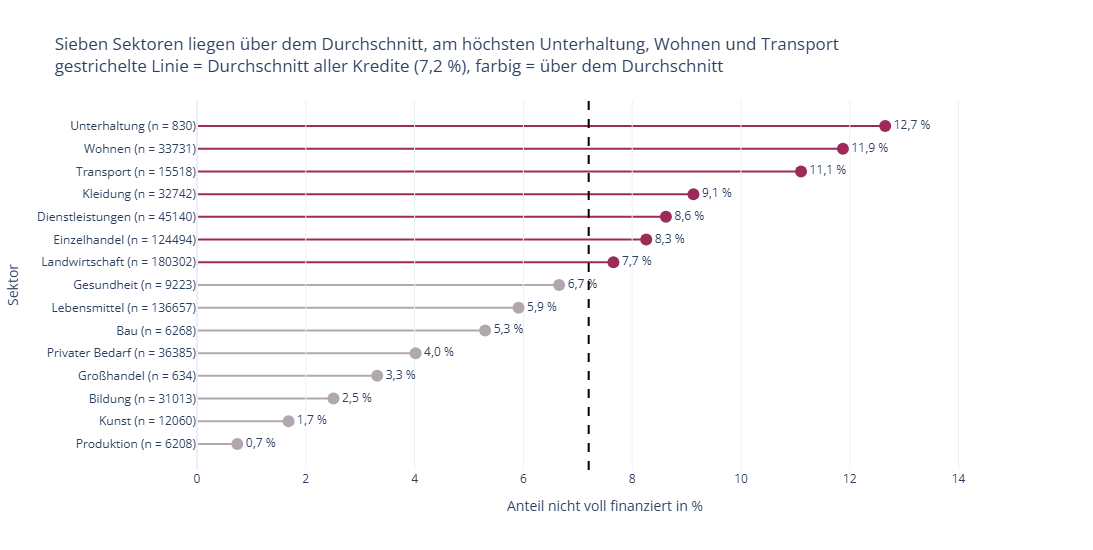

In [35]:
# Farben festlegen: über dem Durchschnitt in Beere, sonst in Grau
farben_map = {"über dem Durchschnitt": "#9C2B5A", "nicht über dem Durchschnitt": "#B0A8AC"}

# Neue Spalte für die Farbe
df_status_sektor.loc[:, "farbe"] = "nicht über dem Durchschnitt"
df_status_sektor.loc[df_status_sektor["anteil_nicht_voll"] > gesamt_nicht_voll, "farbe"] = "über dem Durchschnitt"

# Beschriftung der y-Achse: Sektor mit Anzahl der Kredite, z. B. "Unterhaltung (n = 830)"
df_status_sektor.loc[:, "beschriftung"] = (df_status_sektor.loc[:, "sektor"] + " (n = "
                                           + df_status_sektor.loc[:, "anzahl_kredite"].astype(str) + ")")

# Wert als Text neben jeden Punkt, mit Komma, z. B. "12,7 %"
df_status_sektor.loc[:, "wert_text"] = (df_status_sektor.loc[:, "anteil_nicht_voll"].round(1).astype(str)
                                        .str.replace(".", ",") + " %")

# Sortieren: kleinster Wert zuerst, damit der größte Wert oben steht
df_status_grafik = df_status_sektor.sort_values(by="anteil_nicht_voll", ascending=True)

# Gesamtwert als Text mit Komma, z. B. "7,2"
gesamt_text = str(round(gesamt_nicht_voll, 1)).replace(".", ",")

# Grafik erstellen
scatter_sektor = px.scatter(data_frame=df_status_grafik,
                            x="anteil_nicht_voll",
                            y="beschriftung",
                            color="farbe",
                            color_discrete_map=farben_map,
                            text="wert_text",   # Wert neben jeden Punkt schreiben
                            title="Sieben Sektoren liegen über dem Durchschnitt, am höchsten Unterhaltung, Wohnen und Transport"
                                  + "<br>gestrichelte Linie = Durchschnitt aller Kredite (" + gesamt_text + " %), farbig = über dem Durchschnitt",
                            labels={"anteil_nicht_voll": "Anteil nicht voll finanziert in %", "beschriftung": "Sektor"},
                            template="plotly_white",
                            height=550
                            )

# Punkte größer machen, Wert rechts neben den Punkt setzen
scatter_sektor.update_traces(marker=dict(size=12), textposition="middle right")

# Dünne Linie von 0 bis zum Punkt (für jeden Sektor eine Linie)
werte = df_status_grafik.loc[:, "anteil_nicht_voll"].values
beschriftungen = df_status_grafik.loc[:, "beschriftung"].values
farben = df_status_grafik.loc[:, "farbe"].values

for i in range(len(werte)):
    scatter_sektor.add_shape(type="line",
                             x0=0, x1=werte[i],
                             y0=beschriftungen[i], y1=beschriftungen[i],
                             line_color=farben_map[farben[i]],
                             line_width=2,
                             layer="below")

# Reihenfolge der Sektoren festlegen (von unten nach oben)
scatter_sektor.update_yaxes(categoryorder="array", categoryarray=list(df_status_grafik.loc[:, "beschriftung"]),
                            showgrid=False)

# x-Achse bei 0 beginnen lassen, rechts Platz für die Beschriftung
scatter_sektor.update_xaxes(range=[0, 15])

# Gestrichelte Linie für den Gesamtwert
scatter_sektor.add_vline(x=gesamt_nicht_voll,
                         line_width=2,
                         line_dash="dash",
                         line_color="black")

# Legende ausblenden, Linie und Farbe erklären sich über den Titel
# separators=",." -> Komma als Dezimalzeichen
scatter_sektor.update_layout(showlegend=False, separators=",.")

scatter_sektor.show()

#### Analyse

**Deskriptiver Teil**

Das Punktdiagramm zeigt pro Sektor den Anteil nicht voll finanzierter Kredite
(x-Achse: Anteil in %, y-Achse: Sektor mit Anzahl n). Die gestrichelte Linie steht für den Durchschnitt aller Kredite.
Je weiter rechts ein Punkt, desto öfter wird der beantragte Betrag nicht erreicht.

**Analytischer Teil**

92,8 % aller Kredite erreichen ihren Betrag, 7,2 % nicht. Zwischen den Sektoren gibt es aber deutliche Unterschiede:
- Am häufigsten nicht voll finanziert sind Kredite für Unterhaltung (12,7 %), Wohnen (11,9 %) und Transport (11,1 %),
  also mehr als jeder zehnte.
- Am seltensten betrifft es Produktion (0,7 %), Kunst (1,7 %) und Bildung (2,5 %).
- Insgesamt liegen sieben Sektoren über dem Durchschnitt. Darunter sind auch Landwirtschaft (7,7 %) und
  Einzelhandel (8,3 %), zwei der drei Sektoren mit der größten Summe (4.1).

*Bei Unterhaltung ist Vorsicht geboten, da der Wert auf nur 830 Krediten beruht (ähnlich klein: Großhandel mit 634). Zudem zählt die Kennzahl nur,
**wie oft** ein Betrag verfehlt wird, nicht **um wie viel**: Ein Fehlbetrag von 1 USD wiegt so viel wie einer von 900 USD.*

Woher die Unterschiede kommen, zeigt die Grafik nicht.
*Vermutung: Größere Kredite werden seltener voll finanziert.*

### 4.3 Werden größere Kredite seltener voll finanziert?

#### Daten aufbereiten
Dafür wird jeder Kredit einer Größenklasse zugeordnet und pro Klasse der Anteil nicht voll finanzierter Kredite berechnet.

In [36]:
# Funktion: Größenklasse für einen Kredit bestimmen
def groessen_klasse(betrag):
    if betrag <= 250:
        return "bis 250"
    elif betrag <= 500:
        return "251-500"
    elif betrag <= 1000:
        return "501-1.000"
    elif betrag <= 2000:
        return "1.001-2.000"
    elif betrag <= 5000:
        return "2.001-5.000"
    else:
        return "über 5.000"

In [37]:
# Funktion auf jeden Kredit anwenden
df.loc[:, "loan_size"] = df.loc[:, "loan_amount"].apply(groessen_klasse)

# check
df.loc[:, "loan_size"].unique()

<ArrowStringArray>
['251-500', '501-1.000', 'bis 250', '2.001-5.000', '1.001-2.000',
 'über 5.000']
Length: 6, dtype: str

In [38]:
# Feste Reihenfolge der Größenklassen, von klein nach groß (wird zum Sortieren gebraucht)
reihenfolge_groesse = {"bis 250": 1, "251-500": 2, "501-1.000": 3,
                       "1.001-2.000": 4, "2.001-5.000": 5, "über 5.000": 6}

# Median des beantragten Betrags pro Finanzierungsstatus
df.groupby(by="funding_status", as_index=False).agg(median_kreditbetrag_usd=("loan_amount", "median"))

,funding_status,median_kreditbetrag_usd
0,fully funded,450.0
1,not funded,650.0
2,partially funded,1000.0


In [39]:
# Daten gruppieren: Anzahl und Anteil nicht voll finanzierter Kredite pro Größenklasse
df_groesse = df.groupby(by="loan_size", as_index=False).agg(anzahl_kredite=("loan_size", "count"),
                                                            anteil_nicht_voll=("nicht_voll", "mean"))

# In Prozent umrechnen
df_groesse.loc[:, "anteil_nicht_voll"] = df_groesse.loc[:, "anteil_nicht_voll"] * 100

# In die feste Reihenfolge bringen
df_groesse.loc[:, "reihenfolge"] = df_groesse.loc[:, "loan_size"].map(reihenfolge_groesse)
df_groesse = df_groesse.sort_values(by="reihenfolge")

# Tabelle anzeigen
df_groesse.loc[:, ["loan_size", "anzahl_kredite", "anteil_nicht_voll"]].round(2)

,loan_size,anzahl_kredite,anteil_nicht_voll
4,bis 250,163209,0.56
2,251-500,196360,4.24
3,501-1.000,161943,10.14
0,1.001-2.000,96364,15.51
1,2.001-5.000,43750,14.64
5,über 5.000,9579,13.54


#### Visualisierung

**Vorüberlegung**

Die Größenklassen sind getrennte Gruppen mit unterschiedlicher Breite. Eine Linie würde einen gleichmäßigen Verlauf
zwischen den Klassen vortäuschen. Deshalb zeigt die Grafik Säulen, unter jeder Klasse steht die Anzahl der Kredite (n).

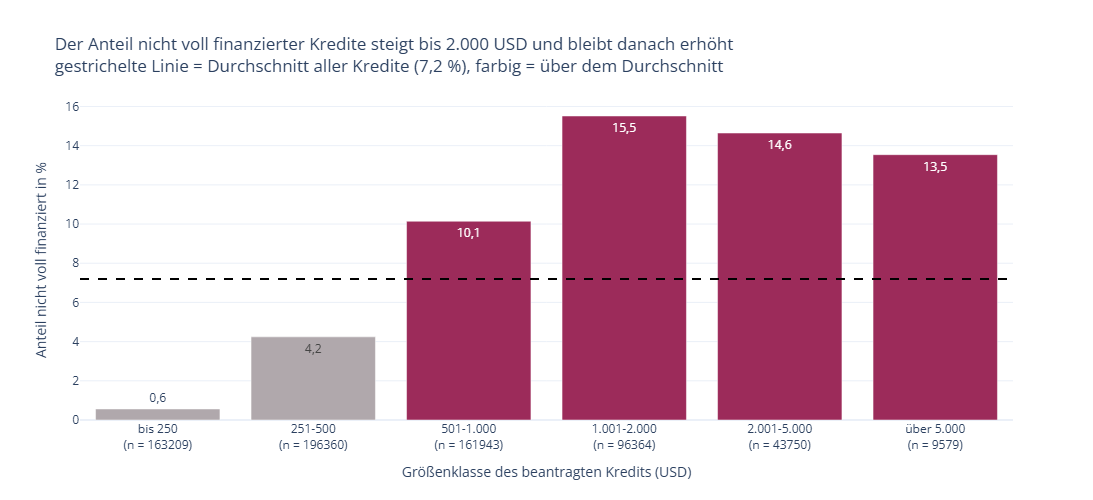

In [40]:
# Neue Spalte für die Farbe: über dem Durchschnitt in Beere, sonst in Grau
df_groesse.loc[:, "farbe"] = "nicht über dem Durchschnitt"
df_groesse.loc[df_groesse["anteil_nicht_voll"] > gesamt_nicht_voll, "farbe"] = "über dem Durchschnitt"

# Beschriftung der x-Achse: Größenklasse mit Anzahl der Kredite in einer zweiten Zeile
df_groesse.loc[:, "beschriftung"] = (df_groesse.loc[:, "loan_size"] + "<br>(n = "
                                     + df_groesse.loc[:, "anzahl_kredite"].astype(str) + ")")

# Grafik erstellen
bar_groesse = px.bar(data_frame=df_groesse,
                     x="beschriftung",
                     y="anteil_nicht_voll",
                     color="farbe",
                     color_discrete_map={"über dem Durchschnitt": "#9C2B5A",
                                         "nicht über dem Durchschnitt": "#B0A8AC"},
                     text_auto=".1f",   # Wert über jede Säule schreiben
                     title="Der Anteil nicht voll finanzierter Kredite steigt bis 2.000 USD und bleibt danach erhöht"
                           + "<br>gestrichelte Linie = Durchschnitt aller Kredite (" + gesamt_text + " %), farbig = über dem Durchschnitt",
                     labels={"beschriftung": "Größenklasse des beantragten Kredits (USD)",
                             "anteil_nicht_voll": "Anteil nicht voll finanziert in %"},
                     template="plotly_white",
                     height=500
                     )

# Reihenfolge der Größenklassen festlegen (von klein nach groß)
bar_groesse.update_xaxes(categoryorder="array", categoryarray=list(df_groesse.loc[:, "beschriftung"]))

# Gestrichelte Linie für den Gesamtwert aus 4.2
bar_groesse.add_hline(y=gesamt_nicht_voll,
                      line_width=2,
                      line_dash="dash",
                      line_color="black")

# separators=",." -> Komma als Dezimalzeichen, z. B. 15,5
bar_groesse.update_layout(showlegend=False, separators=",.")

bar_groesse.show()

#### Analyse

**Deskriptiver Teil**

Das Säulendiagramm zeigt pro Größenklasse den Anteil nicht voll finanzierter Kredite
(x-Achse: Größenklasse mit Anzahl n, y-Achse: Anteil in %). Die gestrichelte Linie steht wieder für den Durchschnitt aller Kredite.

**Analytischer Teil**

Die Vermutung bestätigt sich nur teilweise. Bis zur Klasse 1.001-2.000 USD steigt der Anteil von 0,6 % auf 15,5 %.
In den beiden größten Klassen geht er leicht zurück (14,6 % und 13,5 %), bleibt aber etwa doppelt so hoch
wie der Gesamtwert.
Die Mediane zeigen ein ähnliches Bild: Teilweise finanzierte Kredite haben einen höheren Median (1.000 USD)
als voll finanzierte (450 USD). Gar nicht finanzierte liegen dazwischen (650 USD).

*Eine Ursache belegt das nicht. Außerdem ist die Klasse „über 5.000“ mit 9.579 Krediten deutlich kleiner
als die übrigen (jeweils über 40.000).*

*Die Unterschiede zwischen den Sektoren erklärt die Kredithöhe vermutlich nicht allein: Bildung hat einen hohen Median-Betrag (725 USD), wird aber selten nicht voll finanziert (2,5 %). Wohnen (500 USD) und Transport (450 USD) liegen dagegen deutlich über dem Durchschnitt (Tabellen in 4.1 und 4.2).*

### 4.4 Auffälligkeit: Wer leiht sich das Geld?

#### Daten aufbereiten
In `borrower_genders` stehen oft mehrere Personen, z. B. „female, female, male“.
Jeder Kredit wird deshalb einer Gruppe zugeordnet: nur Frauen, nur Männer, gemischt oder unbekannt.

In [41]:
# Funktion: Geschlechter-Gruppe für einen Kredit bestimmen
def geschlecht_gruppe(text):
    # Leerzeichen entfernen und an den Kommas trennen -> Liste mit einzelnen Personen
    # Beispiel: "female, male" -> ["female", "male"]
    personen = text.replace(" ", "").split(",")

    # Nur Frauen in der Liste
    if "female" in personen and "male" not in personen:
        return "female only"
    # Nur Männer in der Liste
    elif "male" in personen and "female" not in personen:
        return "male only"
    # Frauen und Männer in der Liste
    elif "female" in personen and "male" in personen:
        return "mixed"
    # Alles andere (z. B. "Unknown") -> unbekannt
    else:
        return "Unknown"

In [42]:
# Funktion auf jeden Kredit anwenden
df.loc[:, "gender_group"] = df.loc[:, "borrower_genders"].apply(geschlecht_gruppe)

# check: Wie viele Kredite gibt es pro Gruppe?
df.loc[:, "gender_group"].value_counts()

gender_group
female only    488081
male only      138523
mixed           40380
Unknown          4221
Name: count, dtype: int64

In [43]:
# Und in Prozent
(df.loc[:, "gender_group"].value_counts() / count_rows * 100).round(2)

gender_group
female only    72.72
male only      20.64
mixed           6.02
Unknown         0.63
Name: count, dtype: float64

In [44]:
# Median des beantragten Kreditbetrags pro Gruppe
df.groupby(by="gender_group", as_index=False).agg(median_kreditbetrag_usd=("loan_amount", "median"))

,gender_group,median_kreditbetrag_usd
0,Unknown,625.0
1,female only,425.0
2,male only,625.0
3,mixed,1100.0


**Beobachtung:**
- In diesem Datensatz gehen 72,7 % der Kredite nur an Frauen, 20,6 % nur an Männer und 6,0 % an gemischte Gruppen.
  Bei 0,6 % ist das Geschlecht unbekannt.
- Kredite nur an Frauen sind am kleinsten (Median 425 USD), Kredite nur an Männer liegen bei 625 USD
  und an gemischte Gruppen bei 1.100 USD. *Da gemischte Gruppen immer aus mindestens zwei Personen bestehen,
  erklärt das vermutlich einen Teil ihres höheren Betrags.*

Kleine Kredite werden häufiger voll finanziert (4.3). Gilt das dann auch für Kredite nur an Frauen?

### 4.5 Werden Kredite an Frauen häufiger voll finanziert?

#### Daten aufbereiten

In [45]:
# Feste Reihenfolge der Gruppen (gilt für alle weiteren Auswertungen)
reihenfolge_gruppe = {"female only": 1, "male only": 2, "mixed": 3, "Unknown": 4}

# Daten gruppieren: Anzahl und Anteil nicht voll finanzierter Kredite pro Gruppe
df_gruppe = df.groupby(by="gender_group", as_index=False).agg(anzahl_kredite=("gender_group", "count"),
                                                              anteil_nicht_voll=("nicht_voll", "mean"))

# In Prozent umrechnen
df_gruppe.loc[:, "anteil_nicht_voll"] = df_gruppe.loc[:, "anteil_nicht_voll"] * 100

# Anteil voll finanziert = der Rest bis 100 %
df_gruppe.loc[:, "anteil_voll"] = 100 - df_gruppe.loc[:, "anteil_nicht_voll"]

# In die feste Reihenfolge bringen
df_gruppe.loc[:, "reihenfolge"] = df_gruppe.loc[:, "gender_group"].map(reihenfolge_gruppe)
df_gruppe = df_gruppe.sort_values(by="reihenfolge")

# Tabelle anzeigen
df_gruppe.loc[:, ["gender_group", "anzahl_kredite", "anteil_voll", "anteil_nicht_voll"]].round(2)

,gender_group,anzahl_kredite,anteil_voll,anteil_nicht_voll
1,female only,488081,95.30,4.70
2,male only,138523,84.42,15.58
3,mixed,40380,92.22,7.78
0,Unknown,4221,83.84,16.16


#### Visualisierung

**Vorüberlegung**

Die Kennzahl ist dieselbe wie in 4.2 und 4.3, diesmal als liegende Balken mit einer Linie für den Gesamtwert.

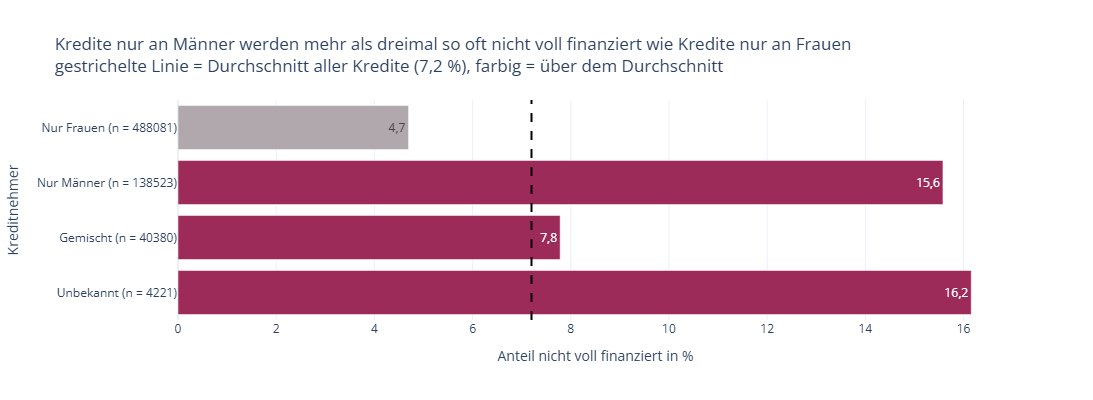

In [46]:
# Neue Spalte für die Farbe: über dem Durchschnitt in Beere, sonst in Grau
df_gruppe.loc[:, "farbe"] = "nicht über dem Durchschnitt"
df_gruppe.loc[df_gruppe["anteil_nicht_voll"] > gesamt_nicht_voll, "farbe"] = "über dem Durchschnitt"

# Gruppen ins Deutsche übersetzen
gruppe_deutsch = {"female only": "Nur Frauen", "male only": "Nur Männer", "mixed": "Gemischt", "Unknown": "Unbekannt"}
df_gruppe.loc[:, "gruppe"] = df_gruppe.loc[:, "gender_group"].map(gruppe_deutsch)

# Beschriftung der y-Achse: Gruppe mit Anzahl der Kredite, z. B. "Nur Frauen (n = 488081)"
df_gruppe.loc[:, "beschriftung"] = (df_gruppe.loc[:, "gruppe"] + " (n = "
                                    + df_gruppe.loc[:, "anzahl_kredite"].astype(str) + ")")

# Sortieren: letzte Gruppe zuerst, damit "Nur Frauen" oben steht
df_gruppe_grafik = df_gruppe.sort_values(by="reihenfolge", ascending=False)

# Grafik erstellen
bar_gruppe = px.bar(data_frame=df_gruppe_grafik,
                    x="anteil_nicht_voll",
                    y="beschriftung",
                    color="farbe",
                    color_discrete_map={"über dem Durchschnitt": "#9C2B5A",
                                        "nicht über dem Durchschnitt": "#B0A8AC"},
                    text_auto=".1f",   # Wert an jeden Balken schreiben
                    title="Kredite nur an Männer werden mehr als dreimal so oft nicht voll finanziert wie Kredite nur an Frauen"
                          + "<br>gestrichelte Linie = Durchschnitt aller Kredite (" + gesamt_text + " %), farbig = über dem Durchschnitt",
                    labels={"anteil_nicht_voll": "Anteil nicht voll finanziert in %", "beschriftung": "Kreditnehmer"},
                    template="plotly_white",
                    height=400
                    )

# Reihenfolge der Gruppen festlegen (von unten nach oben)
bar_gruppe.update_yaxes(categoryorder="array", categoryarray=list(df_gruppe_grafik.loc[:, "beschriftung"]))

# Gestrichelte Linie für den Gesamtwert aus 4.2
bar_gruppe.add_vline(x=gesamt_nicht_voll,
                     line_width=2,
                     line_dash="dash",
                     line_color="black")

# separators=",." -> Komma als Dezimalzeichen, z. B. 4,7
bar_gruppe.update_layout(showlegend=False, separators=",.")

bar_gruppe.show()

#### Analyse

**Deskriptiver Teil**

Das Balkendiagramm zeigt pro Kreditnehmer-Gruppe den Anteil nicht voll finanzierter Kredite
(x-Achse: Anteil in %, y-Achse: Gruppe mit Anzahl n). Die gestrichelte Linie steht für den Durchschnitt aller Kredite.

**Analytischer Teil**

Ja, im Datensatz zeigt sich ein klarer Unterschied:
- Bei Krediten nur an Frauen sind 4,7 % nicht voll finanziert, bei Krediten nur an Männer 15,6 %.
  Der Anteil ist bei Männern also mehr als dreimal so hoch.
- Gemischte Gruppen liegen mit 7,8 % nahe am Gesamtwert.
- Den höchsten Anteil hat die Gruppe „Unbekannt“ (*Unknown*, 16,2 %). Bei diesen Krediten fehlen auch Verwendungszweck und Region (siehe 1.4).
  Das passt zur Prüfung der fehlenden Werte in 1.4.
  *Vermutung (aus den Daten nicht prüfbar): Kredite ohne Beschreibung finden schwerer Geldgeber.*

*Kredite nur an Frauen sind kleiner (Median 425 statt 625 USD, siehe 4.4).
Der Unterschied könnte deshalb auch mit der Kredithöhe zusammenhängen.*

### 4.6 Liegt der Unterschied an der Kredithöhe?
Dazu werden Kredite nur an Frauen und nur an Männer **innerhalb derselben Größenklasse** verglichen.

#### Daten aufbereiten

In [47]:
# Nur die Gruppen "nur Frauen" und "nur Männer" nehmen
frauen_maenner = df.loc[df["gender_group"].isin(["female only", "male only"]), :]

# Daten gruppieren: pro Größenklasse und Gruppe Anzahl und Anteil nicht voll finanzierter Kredite
df_vergleich = frauen_maenner.groupby(by=["loan_size", "gender_group"], as_index=False).agg(
                                                anzahl_kredite=("nicht_voll", "count"),
                                                anteil_nicht_voll=("nicht_voll", "mean"))

# In Prozent umrechnen
df_vergleich.loc[:, "anteil_nicht_voll"] = df_vergleich.loc[:, "anteil_nicht_voll"] * 100

# In die feste Reihenfolge bringen: erst nach Größenklasse, dann nach Gruppe
df_vergleich.loc[:, "reihenfolge"] = df_vergleich.loc[:, "loan_size"].map(reihenfolge_groesse)
df_vergleich = df_vergleich.sort_values(by=["reihenfolge", "gender_group"])

# Tabelle anzeigen
df_vergleich.loc[:, ["loan_size", "gender_group", "anzahl_kredite", "anteil_nicht_voll"]].round(2)

,loan_size,gender_group,anzahl_kredite,anteil_nicht_voll
8,bis 250,female only,132115,0.34
9,bis 250,male only,23242,1.60
4,251-500,female only,157549,3.11
5,251-500,male only,34714,9.24
6,501-1.000,female only,109307,7.07
7,501-1.000,male only,42809,17.95
0,1.001-2.000,female only,59331,10.98
1,1.001-2.000,male only,28446,26.00
2,2.001-5.000,female only,25322,11.28
3,2.001-5.000,male only,7988,31.58


#### 📊 Visualisierung 3 (zur Bewertung)

**Vorüberlegung**

Verglichen werden zwei Gruppen in sechs Größenklassen. Dafür eignet sich ein Punktdiagramm:
pro Klasse ein Punkt für Kredite nur an Frauen und einer für Kredite nur an Männer.
Die Punkte werden nicht verbunden, weil die Größenklassen getrennte Gruppen sind (siehe 4.3).

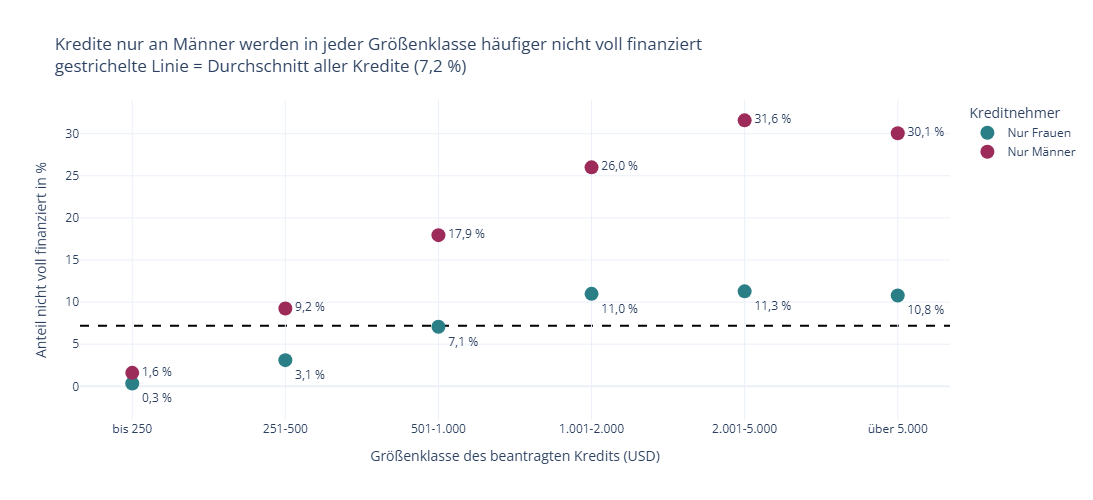

In [48]:
# Gruppen ins Deutsche übersetzen (gruppe_deutsch aus 4.5)
df_vergleich.loc[:, "gruppe"] = df_vergleich.loc[:, "gender_group"].map(gruppe_deutsch)

# Wert als Text neben jeden Punkt, mit Komma, z. B. "26,0 %"
df_vergleich.loc[:, "wert_text"] = (df_vergleich.loc[:, "anteil_nicht_voll"].round(1).astype(str)
                                    .str.replace(".", ",") + " %")

# Grafik erstellen
scatter_vergleich = px.scatter(data_frame=df_vergleich,
                               x="loan_size",
                               y="anteil_nicht_voll",
                               color="gruppe",
                               color_discrete_map={"Nur Männer": "#9C2B5A", "Nur Frauen": "#2A7F86"},
                               text="wert_text",   # Wert neben jeden Punkt schreiben
                               title="Kredite nur an Männer werden in jeder Größenklasse häufiger nicht voll finanziert"
                                     + "<br>gestrichelte Linie = Durchschnitt aller Kredite (" + gesamt_text + " %)",
                               labels={"loan_size": "Größenklasse des beantragten Kredits (USD)",
                                       "anteil_nicht_voll": "Anteil nicht voll finanziert in %",
                                       "gruppe": "Kreditnehmer"},
                               template="plotly_white",
                               height=500
                               )

# Punkte größer machen, Wert rechts neben den Punkt setzen
scatter_vergleich.update_traces(marker=dict(size=14), textposition="middle right")

# Werte der Frauen rechts unter den Punkt setzen, damit sie nicht auf der Linie liegen
scatter_vergleich.update_traces(textposition="bottom right", selector=dict(name="Nur Frauen"))

# y-Achse etwas weiter nach unten, damit der Wert bei "bis 250" nicht abgeschnitten wird
scatter_vergleich.update_yaxes(range=[-4, 34])

# Reihenfolge der Größenklassen festlegen (von klein nach groß, wie in 4.3)
scatter_vergleich.update_xaxes(categoryorder="array", categoryarray=list(reihenfolge_groesse))

# Gestrichelte Linie für den Durchschnitt aller Kredite
# layer="below" -> Linie liegt hinter den Punkten und Beschriftungen
scatter_vergleich.add_hline(y=gesamt_nicht_voll,
                            line_width=2,
                            line_dash="dash",
                            line_color="black",
                            layer="below")

# separators=",." -> Komma als Dezimalzeichen
scatter_vergleich.update_layout(separators=",.")

scatter_vergleich.show()

#### Analyse

**Deskriptiver Teil**

Das Punktdiagramm zeigt pro Größenklasse den Anteil nicht voll finanzierter Kredite, getrennt nach Krediten
nur an Frauen und nur an Männer (x-Achse: Größenklasse, y-Achse: Anteil in %).
Die gestrichelte Linie steht für den Durchschnitt aller Kredite. Je höher ein Punkt, desto öfter wird der Betrag nicht erreicht.

**Analytischer Teil**

Der Unterschied zeigt sich in jeder Größenklasse, zum Beispiel:
- bis 250 USD: 1,6 % bei Männern, 0,3 % bei Frauen
- 1.001-2.000 USD: 26,0 % gegenüber 11,0 %
- 2.001-5.000 USD: 31,6 % gegenüber 11,3 %, also fast dreimal so oft

Die kleinste betrachtete Gruppe (Männer über 5.000 USD) umfasst 1.324 Kredite.

> **Ergebnis:** Auch bei ähnlich großen Krediten bleibt der Unterschied bestehen.
> In Prozentpunkten wird er bei großen Krediten sogar größer. Ganz ausschließen lässt sich die Kredithöhe trotzdem nicht,
> da die Beträge innerhalb einer Klasse noch variieren.

Auffällig ist der Verlauf: Bei Frauen pendelt sich der Anteil ab 1.000 USD bei etwa 11 % ein, bei Männern steigt er
auf über 30 %.

*Das könnte auch den leichten Rückgang in 4.3 erklären: Unter den Krediten nur an Frauen oder nur an Männer
steigt der Anteil der Frauen von der Klasse 1.001-2.000 USD zur Klasse 2.001-5.000 USD von ca. 68 %
(59.331 von 87.777) auf ca. 76 % (25.322 von 33.310). Kredite an Frauen werden häufiger voll finanziert.
Gemischte Gruppen und Unknown wurden dabei nicht betrachtet.*

*Land und Sektor wurden hier nicht berücksichtigt. Es ist also möglich, dass Männer häufiger in Ländern
oder Sektoren Kredite beantragen, in denen Kredite seltener voll finanziert werden.*

### 4.7 Liegt der Unterschied am Sektor oder am Land?
Dazu werden Kredite nur an Frauen und nur an Männer **innerhalb desselben Sektors** und **innerhalb desselben Landes** verglichen.

#### Daten aufbereiten

**Sektor**

In [49]:
# Daten gruppieren: pro Sektor und Gruppe Anzahl und Anteil nicht voll finanzierter Kredite
# frauen_maenner aus 4.6
df_fm_sektor = frauen_maenner.groupby(by=["sektor", "gender_group"], as_index=False).agg(
                                                anzahl_kredite=("nicht_voll", "count"),
                                                anteil_nicht_voll=("nicht_voll", "mean"))

# In Prozent umrechnen
df_fm_sektor.loc[:, "anteil_nicht_voll"] = df_fm_sektor.loc[:, "anteil_nicht_voll"] * 100

# Tabelle anzeigen
df_fm_sektor.round(2)

,sektor,gender_group,anzahl_kredite,anteil_nicht_voll
0,Bau,female only,2769,1.63
1,Bau,male only,3147,8.39
2,Bildung,female only,18800,0.44
3,Bildung,male only,11829,5.76
4,Dienstleistungen,female only,33434,5.75
5,Dienstleistungen,male only,10187,17.92
6,Einzelhandel,female only,105201,5.94
7,Einzelhandel,male only,14514,24.10
8,Gesundheit,female only,5736,4.04
9,Gesundheit,male only,2969,12.63


**Land** (die 10 Länder mit den meisten Krediten nur an Frauen oder nur an Männer)

In [50]:
# Die 10 Länder mit den meisten Krediten nur an Frauen oder nur an Männer
top10_laender = frauen_maenner.loc[:, "country"].value_counts().head(10).index

# Nur Kredite aus diesen 10 Ländern
fm_land = frauen_maenner.loc[frauen_maenner["country"].isin(top10_laender), :]

# Daten gruppieren: pro Land und Gruppe Anzahl und Anteil nicht voll finanzierter Kredite
df_fm_land = fm_land.groupby(by=["country", "gender_group"], as_index=False).agg(
                                                anzahl_kredite=("nicht_voll", "count"),
                                                anteil_nicht_voll=("nicht_voll", "mean"))

# In Prozent umrechnen
df_fm_land.loc[:, "anteil_nicht_voll"] = df_fm_land.loc[:, "anteil_nicht_voll"] * 100

# Tabelle anzeigen
df_fm_land.round(2)

,country,gender_group,anzahl_kredite,anteil_nicht_voll
0,Cambodia,female only,23792,4.37
1,Cambodia,male only,2514,4.73
2,Colombia,female only,12858,13.09
3,Colombia,male only,8360,27.19
4,Ecuador,female only,9900,2.37
5,Ecuador,male only,3277,11.53
6,El Salvador,female only,23437,13.99
7,El Salvador,male only,15875,23.80
8,Kenya,female only,51066,4.20
9,Kenya,male only,15020,13.60


#### Analyse

**Deskriptiver Teil**

Die beiden Tabellen zeigen pro Sektor und pro Land den Anteil nicht voll finanzierter Kredite,
getrennt nach Krediten nur an Frauen und nur an Männer, mit der Anzahl der Kredite.

**Analytischer Teil**

*Sektor:* Kredite nur an Männer werden in **allen 15 Sektoren** häufiger nicht voll finanziert.
- Am größten ist der Unterschied in Prozentpunkten im Einzelhandel (24,1 % gegenüber 5,9 %), bei Kleidung (24,2 % gegenüber 7,5 %)
  und beim Wohnen (23,5 % gegenüber 7,8 %).
- Am kleinsten ist er in der Produktion (1,2 % gegenüber 0,4 %) und in der Kunst (3,9 % gegenüber 1,4 %).
- Großhandel und Unterhaltung beruhen auf höchstens 402 Krediten pro Gruppe.

*Land:* In **9 der 10 Länder** ist der Anteil bei Männern deutlich höher, zum Beispiel in Pakistan
(26,0 % gegenüber 6,5 %) und Uganda (18,0 % gegenüber 4,0 %). Nur in Kambodscha (*Cambodia*) liegen beide
fast gleich (4,7 % gegenüber 4,4 %).

Auch das Land macht einen Unterschied: In Kolumbien (*Colombia*) und El Salvador werden selbst Kredite nur an Frauen
oft nicht voll finanziert (13,1 % und 14,0 %), auf den Philippinen (*Philippines*) kaum (1,6 %).
*Fast ein Drittel der Kredite nur an Frauen kommt von den Philippinen (151.984). Das senkt vermutlich zusätzlich
den Gesamtwert der Frauen (4,7 %, siehe 4.5).*

> **Ergebnis:** Der Unterschied zwischen Frauen und Männern zeigt sich in jedem Sektor und in 9 der 10 größten Länder.
> Er entsteht also nicht nur dadurch, dass Frauen und Männer in unterschiedlichen Sektoren oder Ländern Kredite beantragen.

---

## 5. Interaktives Dashboard
Das Dashboard besteht aus zwei Grafiken und lässt sich nach **Land** und **Kreditnehmer-Gruppe** filtern.
Bei jeder Änderung aktualisieren sich beide Grafiken automatisch.

- **Grafik 1** zeigt die finanzierte Summe pro Sektor. Der Titel nennt die Anzahl der Kredite in der gewählten Auswahl.
- **Grafik 2** zeigt für dieselben Kredite pro Sektor den Anteil nicht voll finanzierter Kredite (wie in 4.2). Der Titel nennt den Anteil
  für die ganze Auswahl. So lässt sich z. B. prüfen, in welchen Ländern Kredite besonders oft nicht voll finanziert werden.
  Die gestrichelte Linie bleibt der Durchschnitt aller Kredite (7,2 %), damit jede Auswahl damit verglichen werden kann.

Beide Grafiken zeigen die Sektoren in derselben Reihenfolge (nach der finanzierten Summe).
So lässt sich direkt ablesen, ob ein Sektor mit viel Geld auch oft seinen Betrag erreicht.

Ist die Anzahl der Kredite klein, beruhen auch die einzelnen Balken nur auf wenigen Krediten.

**Aufbau des Codes:** 1. App erstellen → 2. Layout → 3. Callback → 4. App starten

**Start:** Zelle ausführen, nachdem alle vorherigen Zellen gelaufen sind. Das Dashboard erscheint direkt darunter.

In [51]:
# Auswahl für das Land: "Alle Länder" als erste Auswahl, danach alle Länder alphabetisch sortiert
auswahl_land = ["Alle Länder"] + sorted(df.loc[:, "country"].unique())

# Auswahl für die Kreditnehmer (Gruppen aus 4.4)
# label = das sieht man im Dropdown, value = so heißt die Gruppe in den Daten
auswahl_gruppe = [
    {"label": "Alle", "value": "Alle"},
    {"label": "Nur Frauen", "value": "female only"},
    {"label": "Nur Männer", "value": "male only"},
    {"label": "Gemischt", "value": "mixed"},
    {"label": "Unbekannt", "value": "Unknown"}
]

# Deutsche Namen der Gruppen für den Titel der Grafik
namen_gruppe = {
    "Alle": "Alle Kreditnehmer",
    "female only": "Nur Frauen",
    "male only": "Nur Männer",
    "mixed": "Gemischt",
    "Unknown": "Unbekannt"
}

In [52]:
# 1. App erstellen
kiva_app = Dash(__name__)


# 2. Layout festlegen
kiva_app.layout = html.Div(children=[
                                     # Überschrift
                                     html.H1(children="Kiva-Kredite: Finanzierte Summe und Finanzierungsstatus",
                                             style={"color": "#9C2B5A", "textAlign": "center"}
                                             ),

                                     # Dropdown: Land
                                     html.Label(children="Land auswählen:",
                                                style={"fontWeight": "bold", "color": "#4A3B42"}
                                                ),

                                     dcc.Dropdown(id="dd_land",             # wird für den Callback benötigt
                                                  options=auswahl_land,     # Auswahlmöglichkeiten
                                                  value="Alle Länder",      # Startwert
                                                  clearable=False
                                                  ),

                                     html.Br(),

                                     # Dropdown: Kreditnehmer
                                     html.Label(children="Kreditnehmer auswählen:",
                                                style={"fontWeight": "bold", "color": "#4A3B42"}
                                                ),

                                     dcc.Dropdown(id="dd_gruppe",           # wird für den Callback benötigt
                                                  options=auswahl_gruppe,   # Auswahlmöglichkeiten
                                                  value="Alle",             # Startwert
                                                  clearable=False
                                                  ),

                                     # Grafik 1: Summe pro Sektor
                                     dcc.Graph(id="bar_dashboard",          # wird für den Callback benötigt
                                               figure={}                    # hier wird die aktualisierte Grafik übergeben
                                               ),

                                     html.Br(),

                                     # Grafik 2: Anteil nicht voll finanziert pro Sektor
                                     dcc.Graph(id="bar_status",             # wird für den Callback benötigt
                                               figure={}                    # hier wird die aktualisierte Grafik übergeben
                                               )
                                     ],
                           style={"fontFamily": "Arial", "backgroundColor": "#FDF6F8", "padding": "25px"}
                           )


# 3. Callback erstellen
@kiva_app.callback(
                   # 1. immer die Outputs
                   Output(component_id="bar_dashboard", component_property="figure"),
                   Output(component_id="bar_status", component_property="figure"),

                   # 2. danach die Inputs
                   Input(component_id="dd_land", component_property="value"),
                   Input(component_id="dd_gruppe", component_property="value")
                   )

def update_grafik(selected_land, selected_gruppe):

    # Daten selektieren: mit allen Daten starten (gilt für beide Grafiken)
    df_sel = df

    # Nach Land filtern
    if selected_land != "Alle Länder":
        df_sel = df_sel.loc[df_sel["country"] == selected_land, :]

    # Nach Kreditnehmer-Gruppe filtern
    if selected_gruppe != "Alle":
        df_sel = df_sel.loc[df_sel["gender_group"] == selected_gruppe, :]


    # ----- Grafik 1: Finanzierte Summe pro Sektor -----

    # Daten gruppieren: finanzierte Summe pro Sektor (deutsche Namen aus 4.1)
    df_group = df_sel.groupby(by="sektor", as_index=False).agg(summe_usd=("funded_amount", "sum"))

    # Sortieren: kleinster Wert zuerst, damit der größte Balken oben steht
    df_group = df_group.sort_values(by="summe_usd", ascending=True)

    # In Millionen USD umrechnen (wie in 4.1)
    df_group.loc[:, "summe_mio_usd"] = df_group.loc[:, "summe_usd"] / 1000000

    # Titel festlegen
    if df_sel.shape[0] == 0:
        titel = "Keine Kredite für diese Auswahl"
    else:
        # Titel mit der Anzahl der Kredite in der Auswahl
        titel = ("Finanzierte Summe pro Sektor – " + selected_land + " – " + namen_gruppe[selected_gruppe]
                 + " (n = " + str(df_sel.shape[0]) + " Kredite)")

    # Grafik erstellen
    my_bar = px.bar(data_frame=df_group,
                    x="summe_mio_usd",
                    y="sektor",
                    color_discrete_sequence=["#D4768F"],   # Balken in Altrosa
                    title=titel,
                    labels={"summe_mio_usd": "Finanzierte Summe in Mio. USD", "sektor": "Sektor"},
                    template="plotly_white",
                    height=550
                    )

    # Hintergrund, Schrift und Titelfarbe anpassen
    # separators=",." -> Komma als Dezimalzeichen, z. B. 133,8
    my_bar.update_layout(paper_bgcolor="#FDF6F8",
                         font_color="#4A3B42",
                         title_font_color="#9C2B5A",
                         separators=",.")


    # ----- Grafik 2: Anteil nicht voll finanzierter Kredite pro Sektor -----

    # Daten gruppieren: Anzahl, Anteil nicht voll finanzierter Kredite und Summe pro Sektor (wie in 4.2)
    # Die Summe wird nur zum Sortieren gebraucht
    df_status = df_sel.groupby(by="sektor", as_index=False).agg(anzahl_kredite=("sektor", "count"),
                                                                anteil_nicht_voll=("nicht_voll", "mean"),
                                                                summe_usd=("funded_amount", "sum"))

    # In Prozent umrechnen
    df_status.loc[:, "anteil_nicht_voll"] = df_status.loc[:, "anteil_nicht_voll"] * 100

    # Neue Spalte für die Farbe: über dem Durchschnitt aller Kredite in Beere, sonst in Grau
    # Erst True/False, dann in Text übersetzen
    # (so klappt es auch, wenn die Auswahl keine Kredite enthält)
    df_status.loc[:, "ueber_durchschnitt"] = df_status.loc[:, "anteil_nicht_voll"] > gesamt_nicht_voll
    df_status.loc[:, "farbe"] = df_status.loc[:, "ueber_durchschnitt"].map({True: "über dem Durchschnitt",
                                                                            False: "nicht über dem Durchschnitt"})

    # Beschriftung der y-Achse: Sektor mit Anzahl der Kredite, z. B. "Wohnen (n = 33731)"
    df_status.loc[:, "beschriftung"] = (df_status.loc[:, "sektor"] + " (n = "
                                        + df_status.loc[:, "anzahl_kredite"].astype(str) + ")")

    # Sortieren wie Grafik 1: nach der Summe, kleinste zuerst
    # -> jeder Sektor steht in beiden Grafiken an derselben Stelle
    df_status = df_status.sort_values(by="summe_usd", ascending=True)

    # Titel festlegen
    if df_sel.shape[0] == 0:
        titel_status = "Keine Kredite für diese Auswahl"
    else:
        # Anteil nicht voll finanziert in der ganzen Auswahl, mit Komma, z. B. "22,0"
        anteil_auswahl = df_sel.loc[:, "nicht_voll"].mean() * 100
        anteil_auswahl_text = str(round(anteil_auswahl, 1)).replace(".", ",")

        titel_status = ("Anteil nicht voll finanzierter Kredite pro Sektor – " + selected_land + " – "
                        + namen_gruppe[selected_gruppe] + ": insgesamt " + anteil_auswahl_text + " %"
                        + "<br>gestrichelte Linie = Durchschnitt aller Kredite (" + gesamt_text + " %), farbig = über dem Durchschnitt")

    # Grafik erstellen
    my_bar_status = px.bar(data_frame=df_status,
                           x="anteil_nicht_voll",
                           y="beschriftung",
                           color="farbe",
                           color_discrete_map={"über dem Durchschnitt": "#9C2B5A",
                                               "nicht über dem Durchschnitt": "#B0A8AC"},
                           title=titel_status,
                           labels={"anteil_nicht_voll": "Anteil nicht voll finanziert in %", "beschriftung": "Sektor"},
                           template="plotly_white",
                           height=550
                           )

    # Reihenfolge der Sektoren festlegen (von unten nach oben, wie in Grafik 1)
    my_bar_status.update_yaxes(categoryorder="array", categoryarray=list(df_status.loc[:, "beschriftung"]))

    # Gestrichelte Linie für den Durchschnitt aller Kredite (gesamt_nicht_voll aus 4.2)
    my_bar_status.add_vline(x=gesamt_nicht_voll,
                            line_width=2,
                            line_dash="dash",
                            line_color="black")

    # Legende ausblenden, Linie und Farbe erklären sich über den Titel
    # Hintergrund, Schrift und Titelfarbe wie bei Grafik 1
    my_bar_status.update_layout(showlegend=False,
                                paper_bgcolor="#FDF6F8",
                                font_color="#4A3B42",
                                title_font_color="#9C2B5A",
                                separators=",.")

    # Beide Grafiken zurückgeben (gleiche Reihenfolge wie bei den Outputs)
    return my_bar, my_bar_status


# 4. App starten (direkt im Notebook anzeigen)

kiva_app.run(jupyter_mode="inline", port=8050)

---

## 6. Fazit

### Ergebnisse

> - **Verteilung:** Drei Sektoren (Landwirtschaft, Lebensmittel, Einzelhandel) erhalten knapp zwei Drittel
>   der finanzierten Summe (64,4 %).
> - **Kredithöhe:** Die meisten Kredite sind klein. Der Median liegt bei 500 USD, einzelne sehr große Kredite heben den Mittelwert auf 842 USD.
> - **Finanzierung:** 92,8 % der Kredite erreichen ihren Betrag. Häufiger verfehlt wird er bei Krediten
>   über 500 USD und in den Sektoren Unterhaltung, Wohnen und Transport.
>   Wie oft das in einzelnen Ländern vorkommt, lässt sich im Dashboard (5.) prüfen.
> - **Kreditnehmer:** In diesem Datensatz gehen die meisten Kredite nur an Frauen. Diese Kredite sind kleiner und
>   werden häufiger voll finanziert, auch im Vergleich innerhalb gleicher Größenklassen (4.6)
>   und in allen 15 Sektoren (4.7). In 9 der 10 größten Länder ist der Unterschied deutlich, in Kambodscha gering (4.7).

### Grenzen der Analyse
- Ohne Kredit-Nummer lassen sich doppelte Zeilen nicht sicher als Fehler oder echte Kredite einordnen.
- Bei 8,46 % der Kredite fehlt die Region. Regionale Auswertungen wären deshalb nur eingeschränkt möglich.
- Die Analyse beschreibt Zusammenhänge, aber keine Ursachen.
- Kredithöhe, Sektor und Land wurden für Frauen und Männer jeweils einzeln betrachtet (4.6, 4.7),
  nicht alle gleichzeitig.

### Nächste Fragen
- Was erklärt die Unterschiede zwischen den Sektoren (4.2), wenn nicht die Kredithöhe allein?